# RiskLens: Explaining the LightGBM model with SHAP

**Goal of this notebook:** LightGBM gives better results than my logistic regression, but it's a black box. Here I try to open it up and understand *why* it gives a high or low risk score, both in general and for single applicants.

**What I use:** the LightGBM model from notebook 06 (`models/lgbm_model.joblib`) and the same validation rows as before.

**How I read SHAP (short version for anyone reading this)**
- SHAP splits the model's score for one applicant into one contribution per feature.
- A contribution to the **right / positive** pushes the score towards "default", one to the **left / negative** pushes it towards "no default".
- The numbers are in the model's own units (log-odds), not percentages. More on this below, because it matters.
- SHAP shows what the **model** uses. It doesn't prove that a feature *causes* default in real life.

**What I'll do**
1. Load the model and check it's the right one
2. Compute SHAP values on a sample
3. Overall picture: bar plot and beeswarm
4. Compare with the importance from notebook 06
5. Look at single features
6. Explain two single applicants
7. Check the sensitive features

## 1. Loading the model and the data

In [ ]:
# Step 1: Setup and sanity check

import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

df = pd.read_csv("../data/processed/train_merged.csv")
y = df["TARGET"]
X = df.drop(columns=["TARGET", "SK_ID_CURR"])
X = X.replace([np.inf, -np.inf], np.nan)

cat_cols = X.select_dtypes(exclude="number").columns
for c in cat_cols:
    X[c] = X[c].astype("category")

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model = joblib.load("../models/lgbm_model.joblib")

# sanity check: should be about 0.7635, like in notebook 06
print(roc_auc_score(y_val, model.predict_proba(X_val)[:, 1]))

0.7634728393601152


The AUC on the validation set is **0.7635**, exactly the same as in notebook 06, so the data I rebuilt here matches what the model was trained on. I did this check first because if the data had been different, the explanations would be wrong without me noticing.

## 2. Computing the SHAP values

In [3]:
# Step 2: Compute SHAP values on a sample

X_sample = X_val.sample(5000, random_state=42)
y_sample = y_val.loc[X_sample.index]

explainer = shap.TreeExplainer(model)
sv = explainer(X_sample)
print(sv.values.shape)

(5000, 132)


I took a random sample of **5,000 of the 61,503 validation rows**, because SHAP on all of them would take a long time and 5,000 is enough for the plots. I used `TreeExplainer`, which is made for tree models like LightGBM.

The result has shape **(5000, 132)**: one SHAP value for each of the 5,000 applicants and each of the 132 features.

In [4]:
# for plotting, text columns become numbers (their category codes)

X_plot = X_sample.copy()
for c in cat_cols:
    X_plot[c] = X_plot[c].cat.codes

shap_exp = shap.Explanation(
    values=sv.values,
    base_values=sv.base_values,
    data=X_plot.values,
    feature_names=list(X.columns)
)

For the plots only, I changed the 16 text columns into numbers (their category codes). The model itself is not changed. One consequence: for text columns the colour in the beeswarm below just follows the alphabetical order of the categories, not "high" or "low", so for most of them I only read the left/right spread.

## Before the plots: what the numbers mean (important)

When I trained the model I used `class_weight="balanced"`. Only about 8% of the loans are defaults, so this makes the model treat each default as roughly 11 times more important than a non-default. It stops the model from ignoring the rare class, and it's the reason the recall is decent. But it has a side effect: the model learns as if half of the applicants were defaults. You can see it in notebook 06, where LightGBM started from a 50% default rate, and in the results, where it flags about 31% of applicants even though only 8% really default.

What this means for reading the SHAP plots:
- The **score is not a real probability of default**. A score of 0.9 does not mean a 90% chance of default, it just means "very high compared to the other applicants".
- The SHAP values are in log-odds on this same inflated scale, so the numbers should be compared with each other, not read as percentages.
- What stays valid is the **ranking** of applicants (that's what the AUC measures), **which features matter most** and **whether a feature pushes the risk up or down**. That's what I use SHAP for here.

If I wanted real probabilities I'd need to calibrate the model (map the scores to the real default rate and check it with a calibration curve). I haven't done that yet, it's the next notebook.

In [12]:
for c in ["CODE_GENDER", "NAME_EDUCATION_TYPE", "NAME_CONTRACT_TYPE"]:
    print(c, list(X[c].cat.categories))

CODE_GENDER ['F', 'M', 'XNA']
NAME_EDUCATION_TYPE ['Academic degree', 'Higher education', 'Incomplete higher', 'Lower secondary', 'Secondary / secondary special']
NAME_CONTRACT_TYPE ['Cash loans', 'Revolving loans']


## 3. The big picture: which features matter overall

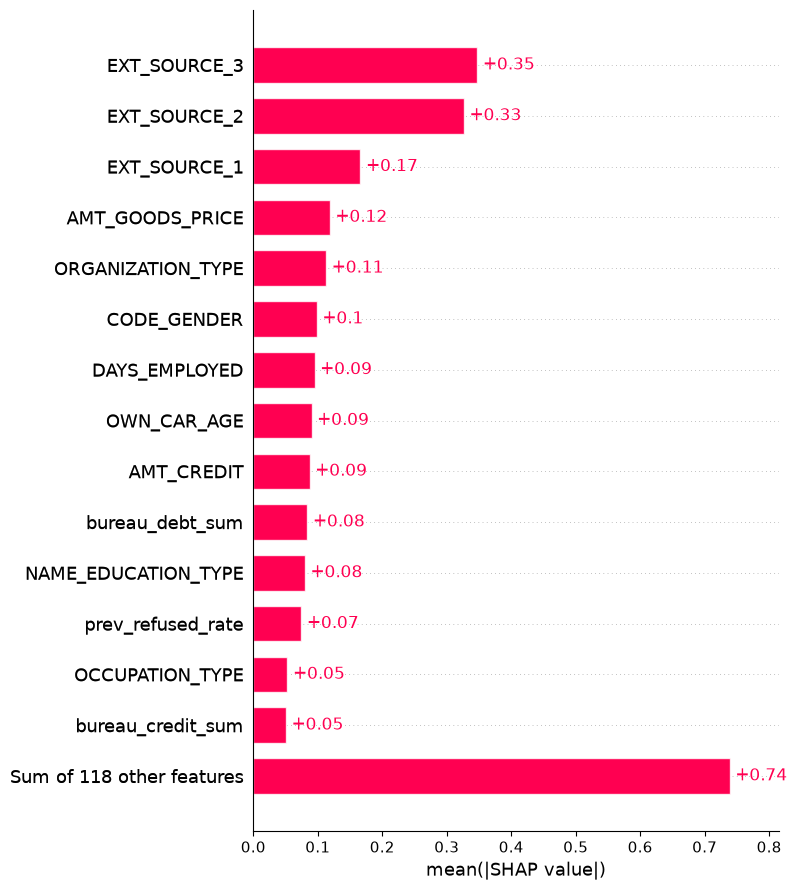

In [5]:
# Step 3: Global picture, which features matter overall

shap.plots.bar(shap_exp, max_display=15, show=False)
plt.tight_layout()
plt.savefig("../reports/figures/shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

**Bar plot:** the average size of each feature's effect on the score (mean absolute SHAP value). The longer the bar, the more the model relies on that feature.

- `EXT_SOURCE_3` (0.35) and `EXT_SOURCE_2` (0.33) are by far the biggest, then `EXT_SOURCE_1` (0.17). The three external scores matter much more than anything else, same as in the correlations from notebook 01 and in the baseline.
- After those come `AMT_GOODS_PRICE` (0.12), `ORGANIZATION_TYPE` (0.11), `CODE_GENDER` (0.10), then `DAYS_EMPLOYED`, `OWN_CAR_AGE` and `AMT_CREDIT` (0.09 each).
- Three of my own features from the bureau and previous application tables are in this top 15: `bureau_debt_sum` (0.08), `prev_refused_rate` (0.07) and `bureau_credit_sum` (0.05).
- The last bar shows that the **118 other features together add up to 0.74**, more than any single feature. So the model uses a lot of small signals, not just the top few.

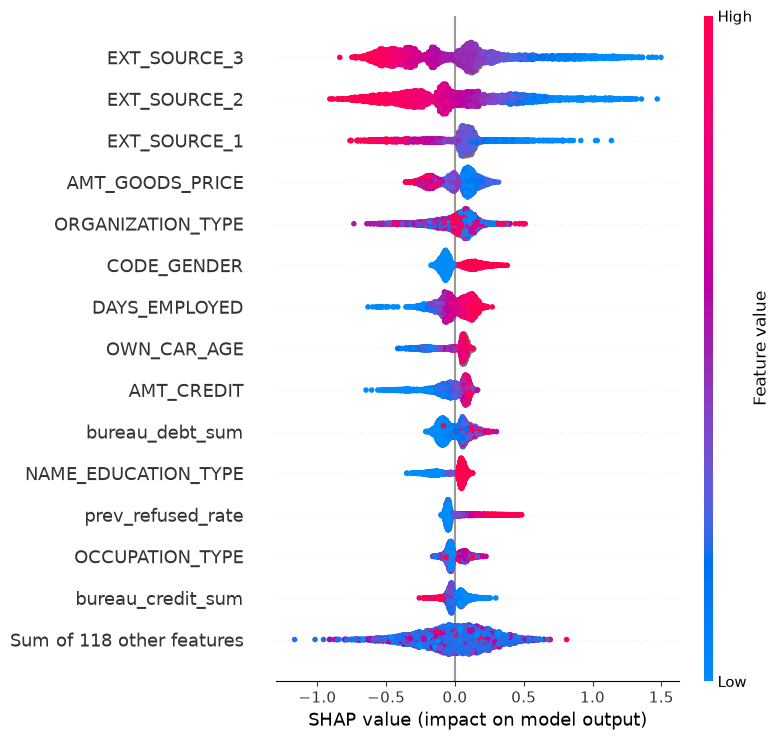

In [6]:
shap.plots.beeswarm(shap_exp, max_display=15, show=False)
plt.tight_layout()
plt.savefig("../reports/figures/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

**Beeswarm plot:** each dot is one applicant. A dot on the right pushes that person's risk score up, on the left it pushes it down. Red means a high value of the feature, blue a low value. This shows the *direction* of each feature, which the bar plot can't.

What I can read from it:
- **`EXT_SOURCE_1/2/3`:** red dots on the left, blue dots on the right. A high external score means lower risk, a low score means higher risk. The blue dots go far to the right (up to about +1.5 for `EXT_SOURCE_3` and `EXT_SOURCE_2`), so a very low score is a strong warning sign.
- **`AMT_GOODS_PRICE` and `AMT_CREDIT` go in opposite directions:** a high goods price pushes risk down, a high credit amount pushes it up. These two columns are almost the same number for most loans, and I saw the same thing with opposite coefficients in the baseline. My guess is that the model uses the *difference* between them, but I haven't checked that.
- **`prev_refused_rate`:** the red dots go to the right (up to about +0.5). A higher share of refused previous applications means higher risk, which matches what I found in notebook 03.
- **`bureau_debt_sum`:** higher debt tends to push the risk up, but the pattern is messy.
- **`bureau_credit_sum`:** the red dots (high total credit) are on the left, so a large amount of credit at other banks goes with lower risk.
- **`CODE_GENDER`:** two clearly separated groups. The red group is on the right (higher risk) and the blue group on the left. With the alphabetical order, red is M and blue is F, so the model gives men a higher risk score than women. This is the first thing I want to look at in the fairness notebook.
- **`NAME_EDUCATION_TYPE`:** a blue group on the left and a red group slightly to the right. With the alphabetical order, higher education pushes the risk down and secondary education pushes it up.
- **`DAYS_EMPLOYED`:** looked at more closely in section 5.
- For `ORGANIZATION_TYPE` and `OCCUPATION_TYPE` the colours are only the alphabetical order, so I'm not reading them as high or low.

## 4. Comparing with the importance from notebook 06

In [7]:
# Step 4: Compare with the gain importance from notebook 06

mean_abs = pd.Series(np.abs(sv.values).mean(axis=0), index=X.columns).sort_values(ascending=False)
print(mean_abs.head(15))

EXT_SOURCE_3           0.347343
EXT_SOURCE_2           0.326568
EXT_SOURCE_1           0.166091
AMT_GOODS_PRICE        0.118572
ORGANIZATION_TYPE      0.112844
CODE_GENDER            0.098415
DAYS_EMPLOYED          0.094921
OWN_CAR_AGE            0.090218
AMT_CREDIT             0.087213
bureau_debt_sum        0.083735
NAME_EDUCATION_TYPE    0.079953
prev_refused_rate      0.074405
OCCUPATION_TYPE        0.052861
bureau_credit_sum      0.050592
NAME_FAMILY_STATUS     0.049143
dtype: float64


Top 15 by mean absolute SHAP value, next to the rank from LightGBM's gain importance in notebook 06:

| Feature | SHAP rank | Gain rank (notebook 06) |
|---|---|---|
| EXT_SOURCE_3 | 1 | 1 |
| EXT_SOURCE_2 | 2 | 2 |
| EXT_SOURCE_1 | 3 | 4 |
| AMT_GOODS_PRICE | 4 | 9 |
| ORGANIZATION_TYPE | 5 | 3 |
| CODE_GENDER | 6 | 13 |
| DAYS_EMPLOYED | 7 | 5 |
| OWN_CAR_AGE | 8 | 10 |
| AMT_CREDIT | 9 | 6 |
| bureau_debt_sum | 10 | 14 |
| NAME_EDUCATION_TYPE | 11 | 11 |
| prev_refused_rate | 12 | 8 |
| OCCUPATION_TYPE | 13 | 7 |
| bureau_credit_sum | 14 | 15 |
| NAME_FAMILY_STATUS | 15 | outside top 15 |

- 14 of the 15 features are the same in both lists and the top two are identical, so both methods agree on the main picture.
- The biggest moves: `CODE_GENDER` (13th to 6th) and `AMT_GOODS_PRICE` (9th to 4th) go up with SHAP, and `OCCUPATION_TYPE` (7th to 13th) goes down. `AMT_ANNUITY` was 12th by gain but isn't in the SHAP top 15, and `NAME_FAMILY_STATUS` is new.
- I trust SHAP more here, because gain can be inflated for text columns with many categories. That might be why `OCCUPATION_TYPE` drops, but I'm not sure.
- Gender being so much higher with SHAP than with gain is one more reason to look at it carefully.

## 5. How single features work

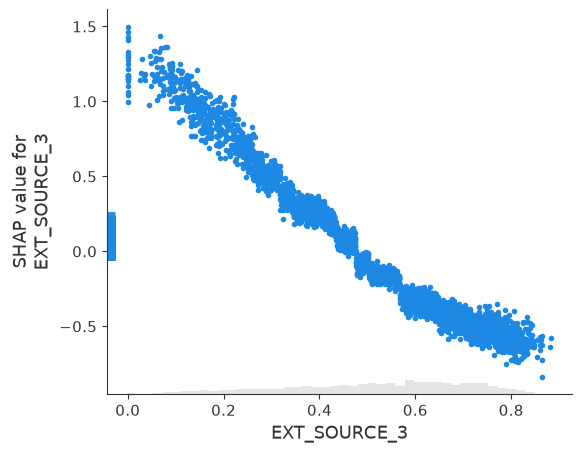

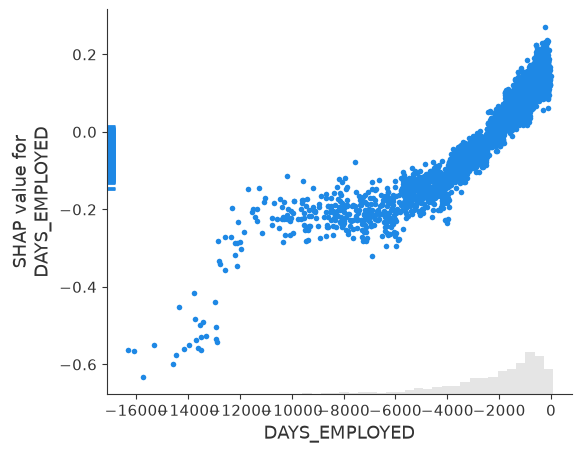

In [8]:
# Step 5: How one feature works (dependence plots)

shap.plots.scatter(shap_exp[:, "EXT_SOURCE_3"], show=False)
plt.savefig("../reports/figures/shap_ext_source_3.png", dpi=150, bbox_inches="tight")
plt.show()

shap.plots.scatter(shap_exp[:, "DAYS_EMPLOYED"], show=False)
plt.savefig("../reports/figures/shap_days_employed.png", dpi=150, bbox_inches="tight")
plt.show()

These plots show one feature on the x-axis and its effect on the score (SHAP value) on the y-axis. Each dot is an applicant, and the grey bars at the bottom show how many applicants there are at each value.

**`EXT_SOURCE_3`:** an almost straight line going down. A very low score (around 0.1) pushes the risk score up by about +1, and a high score (0.8) pushes it down by about 0.5. The effect crosses zero at around 0.5. There are no steps or jumps, the relationship is smooth, which fits the straight-line correlation from notebook 01. The block of dots at the far left is the applicants with a **missing** `EXT_SOURCE_3`. They get an effect close to zero, slightly positive, so missing doesn't look like a strong signal on its own here.

**`DAYS_EMPLOYED`:** this is days before the application, so 0 means "just started" and -10,000 is about 27 years. The effect rises steadily as the employment gets shorter: people who started their job recently get pushed towards higher risk (up to about +0.2), while people employed for more than about 16 years (below -6,000) are fairly flat around -0.2. A few people with 40+ years go lower, down to about -0.6, but there are very few of them. The block on the far left is the applicants whose value was missing (the 365243 placeholder I replaced in notebook 01). They get a small effect between about -0.14 and 0. I still haven't checked who those people are, so that's still on my list.

## 6. Two single applicants

I took the riskiest and the safest applicant in the sample, so these are extreme cases, not typical ones.

high risk: score 0.9053973018206414 | really defaulted: 1
low risk: score 0.019042525538126097 | really defaulted: 0


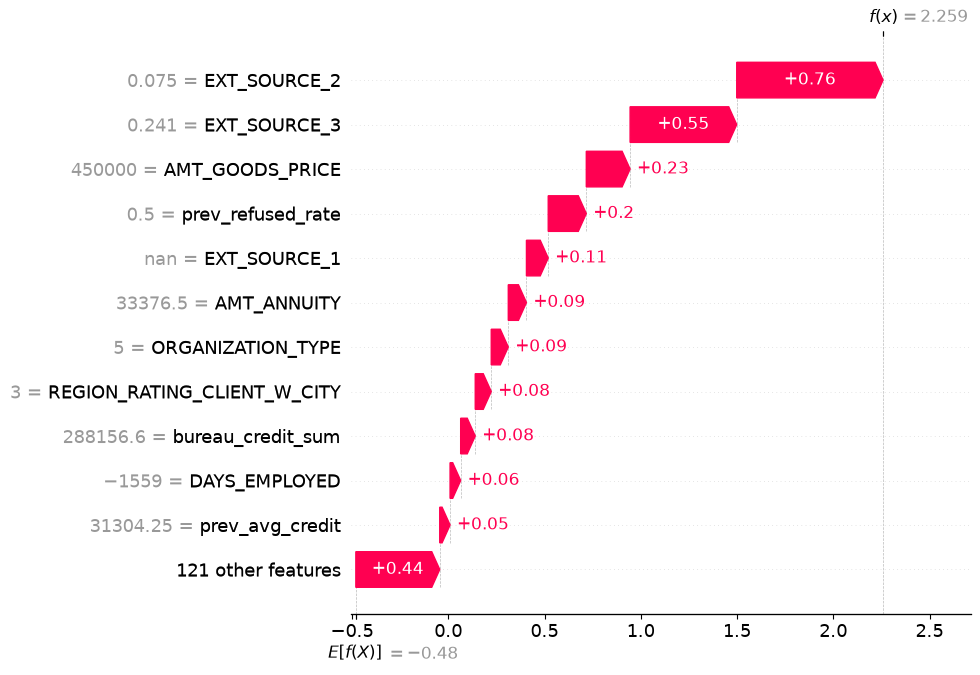

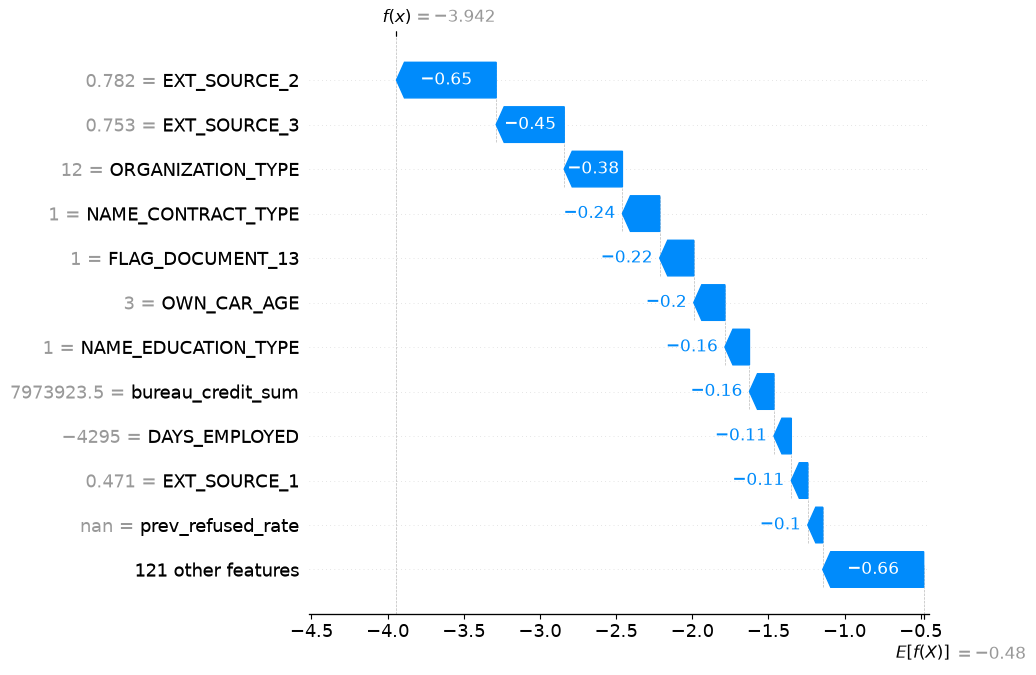

In [9]:
# Step 6: Explain single applicants

probs = model.predict_proba(X_sample)[:, 1]
i_high = int(np.argmax(probs))   # the riskiest applicant in the sample
i_low = int(np.argmin(probs))    # the safest one

print("high risk: score", probs[i_high], "| really defaulted:", y_sample.iloc[i_high])
print("low risk: score", probs[i_low], "| really defaulted:", y_sample.iloc[i_low])

shap.plots.waterfall(shap_exp[i_high], max_display=12, show=False)
plt.savefig("../reports/figures/shap_waterfall_high.png", dpi=150, bbox_inches="tight")
plt.show()

shap.plots.waterfall(shap_exp[i_low], max_display=12, show=False)
plt.savefig("../reports/figures/shap_waterfall_low.png", dpi=150, bbox_inches="tight")
plt.show()


A waterfall plot starts at the average score of the model (E[f(X)] = -0.48, at the bottom) and shows how each feature moves this one person's score up (red) or down (blue), until the final score f(x) at the top. The values are in log-odds, as explained above.

**Highest risk applicant (model score 0.91, really defaulted: yes):** f(x) = 2.26, far above the average of -0.48.
- The biggest pushes up are the two external scores: `EXT_SOURCE_2` = 0.075 (+0.76) and `EXT_SOURCE_3` = 0.241 (+0.55). Both are very low.
- Then `AMT_GOODS_PRICE` = 450,000 (+0.23) and `prev_refused_rate` = 0.5 (+0.20), so half of this person's earlier applications were refused.
- `EXT_SOURCE_1` is **missing**, and that alone pushes the risk up by +0.11.
- Nothing in the top 12 pushes the risk down.

**Lowest risk applicant (model score 0.02, really defaulted: no):** f(x) = -3.94.
- Again the external scores are the biggest: `EXT_SOURCE_2` = 0.782 (-0.65) and `EXT_SOURCE_3` = 0.753 (-0.45), both high.
- Then the organization type (code 12, -0.38), the contract type (code 1, which should be revolving loans, -0.24), a newer car (`OWN_CAR_AGE` = 3 years, -0.20), the education type (code 1, -0.16) and a very large `bureau_credit_sum` of about 8 million (-0.16).
- `FLAG_DOCUMENT_13` = 1 lowers the risk by 0.22. I don't have an explanation for that one, so I won't read anything into it.
- Nothing in the top 12 pushes the risk up.

These are the two most extreme applicants out of 5,000, and the model got both right. That doesn't tell me much about how good the model is overall, it's just a way to see how the explanations work. In both cases the story is dominated by the external scores, which matches the global plots.

In [10]:
print(X_sample.iloc[i_high][cat_cols])

NAME_CONTRACT_TYPE                               Cash loans
CODE_GENDER                                               F
FLAG_OWN_CAR                                              N
FLAG_OWN_REALTY                                           Y
NAME_TYPE_SUITE                               Unaccompanied
NAME_INCOME_TYPE                                    Working
NAME_EDUCATION_TYPE           Secondary / secondary special
NAME_FAMILY_STATUS                     Single / not married
NAME_HOUSING_TYPE                         House / apartment
OCCUPATION_TYPE                                 Sales staff
WEEKDAY_APPR_PROCESS_START                           FRIDAY
ORGANIZATION_TYPE                    Business Entity Type 3
FONDKAPREMONT_MODE                                      NaN
HOUSETYPE_MODE                                          NaN
WALLSMATERIAL_MODE                                      NaN
EMERGENCYSTATE_MODE                                     NaN
Name: 196834, dtype: object


The waterfall shows text columns as codes, so this prints the real values for the high-risk applicant: a woman on a cash loan, working as sales staff, with secondary education, single, at a "Business Entity Type 3" company, and no car. The code 5 shown for `ORGANIZATION_TYPE` in the waterfall is this "Business Entity Type 3".

## 7. The sensitive features

In [11]:
# Step 7: Check the sensitive features (this feeds the fairness notebook)

for col in ["CODE_GENDER", "AGE", "DAYS_BIRTH", "ORGANIZATION_TYPE"]:
    rank = list(mean_abs.index).index(col) + 1
    print(col, "rank:", rank, "| mean |SHAP|:", round(mean_abs[col], 4))

CODE_GENDER rank: 6 | mean |SHAP|: 0.0984
AGE rank: 26 | mean |SHAP|: 0.0241
DAYS_BIRTH rank: 20 | mean |SHAP|: 0.0343
ORGANIZATION_TYPE rank: 5 | mean |SHAP|: 0.1128


| Feature | Rank (of 132) | Mean abs SHAP |
|---|---|---|
| ORGANIZATION_TYPE | 5 | 0.113 |
| CODE_GENDER | 6 | 0.098 |
| DAYS_BIRTH | 20 | 0.034 |
| AGE | 26 | 0.024 |

- **`CODE_GENDER` is 6th**, ahead of `DAYS_EMPLOYED`, `AMT_CREDIT` and my bureau and previous application features. That's a lot for a feature that says nothing about someone's ability to pay, and in lending it's a sensitive attribute: in many countries, including in the EU, using gender in credit decisions is restricted or not allowed. I'll look into it in the fairness notebook, including what happens to the results if I take it out.
- **Age is in the model twice**, as `DAYS_BIRTH` (20th) and as my own `AGE` column (26th), which is the same information. Each looks small, but adding them together (roughly, it's not exact) gives about 0.06, around the level of `OCCUPATION_TYPE`. So to test the model without age, I have to remove both.

In [13]:
print("average model score:", probs.mean())
print("real default rate:", y_sample.mean())

average model score: 0.4013524054795802
real default rate: 0.081


## Summary

**What I did**
- Computed SHAP values for the LightGBM model on a 5,000-row sample of the validation set
- Looked at the overall picture, single features and two single applicants

**What I found**
- `EXT_SOURCE_1/2/3` dominate. Low scores push the risk up strongly, and the effect of `EXT_SOURCE_3` is smooth and almost a straight line
- Shorter employment and a higher share of refused previous applications push the risk up
- Three of my own features (`bureau_debt_sum`, `prev_refused_rate`, `bureau_credit_sum`) are in the top 15, so the work on the extra tables was worth it
- SHAP and gain importance agree on 14 of the 15 top features
- `CODE_GENDER` ranks 6th and age is in the model twice, so I need to check fairness

**Limits of this analysis**
- The scores are **not calibrated probabilities** (I used balanced class weights), so I only use SHAP for the ranking, the direction and the relative size of effects
- SHAP explains what the model does, not what causes default in real life
- Only 5,000 validation rows, and text columns are shown as category codes in the plots

**Next:** `08_calibration` (turn the scores into real probabilities), then `09_fairness` (performance by gender and age group, and a test without the sensitive features)